# Exploratory Data Analysis and Insights on the Automobile Dataset Using Pandas

### Beginner-to-Intermediate Pandas Practice Notebook

This notebook is designed for students who are learning how to clean and explore mixed numerical and categorical data using **Pandas**.

The exercises begin with basic DataFrame operations and gradually introduce:

- Loading a CSV file with custom missing-value markers
- Inspecting rows, columns, and data types
- Finding and handling missing values
- Selecting, filtering, and sorting records
- Exploring vehicle categories
- Calculating descriptive statistics
- Grouping and aggregating data
- Creating derived columns
- Examining correlations
- Creating basic visualizations
- Exporting cleaned data


## About the Dataset

The **Automobile.csv** dataset contains information about **205 automobiles** from the 1985 model year.

It contains **26 columns** describing vehicle specifications, fuel economy, insurance risk, and price.

### Main Column Groups

| Group | Example columns | Description |
|---|---|---|
| Vehicle identity | `make`, `fuel_type`, `body_style` | Manufacturer and vehicle categories |
| Size and weight | `wheel_base`, `length`, `width`, `curb_weight` | Physical measurements and vehicle weight |
| Engine | `engine_type`, `num_cylinders`, `engine_size`, `horsepower` | Engine design and performance information |
| Fuel economy | `city_mpg`, `highway_mpg` | City and highway fuel efficiency |
| Cost and risk | `price`, `symboling`, `normalized_losses` | Vehicle price and insurance-risk information |

### Important Observation

The original dataset uses a question mark (`?`) to represent missing information. When loading the CSV, use the `na_values` parameter so Pandas treats these markers as missing values.

The original hyphenated field names were converted to lowercase names with underscores to make them easier to use in Python.

**Source:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/10/automobile)  
**License:** CC BY 4.0


## Learning Goal

By completing this assignment, you will practice a complete beginner-to-intermediate data-cleaning and exploration workflow. You will work with missing values, compare vehicle groups, calculate useful derived measures, and summarize the relationships between price, performance, and fuel economy.


## 1. Loading and Understanding the Dataset

### Question 1
Import the Pandas library using the alias `pd` and read **Automobile.csv** into a DataFrame named `df`. Use `na_values='?'` so question marks are treated as missing values.


In [8]:
import pandas as pd
df=pd.read_csv('Automobile.csv',na_values="?")

### Question 2
Display the first **5 rows** of the dataset.


In [9]:
df.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


### Question 3
Display the last **5 rows** of the dataset.


In [10]:
df.tail()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
200,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,23,28,16845.0
201,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160.0,5300.0,19,25,19045.0
202,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134.0,5500.0,18,23,21485.0
203,-1,95.0,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106.0,4800.0,26,27,22470.0
204,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,19,25,22625.0


### Question 4
Find the total number of **rows and columns** in the dataset.


In [11]:
print('No of Rows:',df.shape[0])
print('No of Columns:',df.shape[1])

No of Rows: 205
No of Columns: 26


### Question 5
Display all the **column names** in the dataset.


In [12]:
df.columns

Index(['symboling', 'normalized_losses', 'make', 'fuel_type', 'aspiration',
       'num_doors', 'body_style', 'drive_wheels', 'engine_location',
       'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_type',
       'num_cylinders', 'engine_size', 'fuel_system', 'bore', 'stroke',
       'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg',
       'highway_mpg', 'price'],
      dtype='object')

### Question 6
Display the **data type of each column**.


In [13]:
df.dtypes

symboling              int64
normalized_losses    float64
make                  object
fuel_type             object
aspiration            object
num_doors             object
body_style            object
drive_wheels          object
engine_location       object
wheel_base           float64
length               float64
width                float64
height               float64
curb_weight            int64
engine_type           object
num_cylinders         object
engine_size            int64
fuel_system           object
bore                 float64
stroke               float64
compression_ratio    float64
horsepower           float64
peak_rpm             float64
city_mpg               int64
highway_mpg            int64
price                float64
dtype: object

### Question 7
Display a complete summary of the DataFrame using `info()`.


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          203 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    object 
 16  engine_size        205 non

## 2. Checking and Handling Missing Values

### Question 8
Display the number of **missing values in each column**.


In [15]:
df.isna().sum()

symboling             0
normalized_losses    41
make                  0
fuel_type             0
aspiration            0
num_doors             2
body_style            0
drive_wheels          0
engine_location       0
wheel_base            0
length                0
width                 0
height                0
curb_weight           0
engine_type           0
num_cylinders         0
engine_size           0
fuel_system           0
bore                  4
stroke                4
compression_ratio     0
horsepower            2
peak_rpm              2
city_mpg              0
highway_mpg           0
price                 4
dtype: int64

### Question 9
Display only the columns that contain **at least one missing value**.


In [18]:
# print(df.loc[:,df.isnull().any()])  # for rows 

print(df.columns[df.isnull().any()])

Index(['normalized_losses', 'num_doors', 'bore', 'stroke', 'horsepower',
       'peak_rpm', 'price'],
      dtype='object')


### Question 10
Calculate the **total number of missing values** in the entire DataFrame.


In [21]:
print(df.isna().sum().sum())

59


### Question 11
Display all rows where the **price** is missing.


In [23]:
print(df[df['price'].isnull()])

     symboling  normalized_losses     make fuel_type aspiration num_doors  \
9            0                NaN     audi       gas      turbo       two   
44           1                NaN    isuzu       gas        std       two   
45           0                NaN    isuzu       gas        std      four   
129          1                NaN  porsche       gas        std       two   

    body_style drive_wheels engine_location  wheel_base  ...  engine_size  \
9    hatchback          4wd           front        99.5  ...          131   
44       sedan          fwd           front        94.5  ...           90   
45       sedan          fwd           front        94.5  ...           90   
129  hatchback          rwd           front        98.4  ...          203   

     fuel_system  bore  stroke compression_ratio horsepower  peak_rpm  \
9           mpfi  3.13    3.40               7.0      160.0    5500.0   
44          2bbl  3.03    3.11               9.6       70.0    5400.0   
45       

### Question 12
Create a DataFrame named `df_clean` by removing rows with missing values in `price` or `horsepower`. Display its shape.


In [25]:
df_clean =df.dropna(subset=['price','horsepower'])
print(df_clean.shape)

(199, 26)


## 3. Selecting Rows and Columns

### Question 13
Select and display only the **make** column from `df_clean`.


In [26]:
df_clean['make']

0      alfa-romero
1      alfa-romero
2      alfa-romero
3             audi
4             audi
          ...     
200          volvo
201          volvo
202          volvo
203          volvo
204          volvo
Name: make, Length: 199, dtype: object

### Question 14
Select and display the **make, body_style, horsepower, city_mpg, and price** columns.


In [28]:
df_clean[['make', 'body_style', 'horsepower', 'city_mpg','price']]

,make,body_style,horsepower,city_mpg,price
0,alfa-romero,convertible,111.0,21,13495.0
1,alfa-romero,convertible,111.0,21,16500.0
2,alfa-romero,hatchback,154.0,19,16500.0
3,audi,sedan,102.0,24,13950.0
4,audi,sedan,115.0,18,17450.0
...,...,...,...,...,...
200,volvo,sedan,114.0,23,16845.0
201,volvo,sedan,160.0,19,19045.0
202,volvo,sedan,134.0,18,21485.0
203,volvo,sedan,106.0,26,22470.0


### Question 15
Using `iloc`, display the first **5 rows and first 6 columns** of `df_clean`.


In [29]:
df_clean.iloc[:5,:6]

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors
0,3,NaN,alfa-romero,gas,std,two
1,3,NaN,alfa-romero,gas,std,two
2,1,NaN,alfa-romero,gas,std,two
3,2,164.0,audi,gas,std,four
4,2,164.0,audi,gas,std,four


### Question 16
Using `loc`, display rows **10 to 15** for the columns **make, engine_size, horsepower, and price**.


In [31]:
df.loc[10:15,['make','engine_size','horsepower','price']]

,make,engine_size,horsepower,price
10,bmw,108,101.0,16430.0
11,bmw,108,101.0,16925.0
12,bmw,164,121.0,20970.0
13,bmw,164,121.0,21105.0
14,bmw,164,121.0,24565.0
15,bmw,209,182.0,30760.0


## 4. Exploring Categories and Descriptive Statistics

### Question 17
Display all the **unique automobile manufacturers** in the dataset.

In [32]:
print(df['make'].unique())

['alfa-romero' 'audi' 'bmw' 'chevrolet' 'dodge' 'honda' 'isuzu' 'jaguar'
 'mazda' 'mercedes-benz' 'mercury' 'mitsubishi' 'nissan' 'peugot'
 'plymouth' 'porsche' 'renault' 'saab' 'subaru' 'toyota' 'volkswagen'
 'volvo']


### Question 18
Count the number of automobiles produced by each manufacturer using `value_counts()`.


In [33]:
df['make'].value_counts()

make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
volkswagen       12
subaru           12
peugot           11
volvo            11
dodge             9
mercedes-benz     8
bmw               8
audi              7
plymouth          7
saab              6
porsche           5
isuzu             4
jaguar            3
chevrolet         3
alfa-romero       3
renault           2
mercury           1
Name: count, dtype: int64

### Question 19
Display all unique **body styles** and count the number of automobiles in each style.


In [35]:
print(df['body_style'].unique())
print(df['body_style'].value_counts())

['convertible' 'hatchback' 'sedan' 'wagon' 'hardtop']
body_style
sedan          96
hatchback      70
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64


### Question 20
Count the values in the **fuel_type** and **aspiration** columns.


In [36]:
print(df["fuel_type"].value_counts())
print(df["aspiration"].value_counts())

fuel_type
gas       185
diesel     20
Name: count, dtype: int64
aspiration
std      168
turbo     37
Name: count, dtype: int64


### Question 21
Display descriptive statistics for the numeric columns in `df_clean` using `describe()`.


In [37]:
df_clean.describe()

,symboling,normalized_losses,wheel_base,length,width,height,curb_weight,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
count,199.000000,164.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,195.000000,195.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,0.839196,122.000000,98.824121,174.151256,65.882412,53.775879,2556.030151,126.824121,3.329385,3.250308,10.178995,103.396985,5117.587940,25.201005,30.683417,13243.432161
std,1.257009,35.442168,6.090838,12.371905,2.110996,2.447039,519.855544,41.752932,0.271866,0.314115,4.022424,37.553843,480.521824,6.451826,6.849410,7978.707609
min,-2.000000,65.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,94.000000,94.500000,166.550000,64.100000,52.000000,2157.000000,97.500000,3.150000,3.110000,8.550000,70.000000,4800.000000,19.000000,25.000000,7775.000000
50%,1.000000,115.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,119.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10345.000000
75%,2.000000,150.000000,102.400000,183.500000,66.700000,55.550000,2930.500000,143.000000,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16501.500000
max,3.000000,256.000000,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000


### Question 22
Calculate the **mean price**, **maximum horsepower**, and **minimum city fuel economy**.


In [38]:
print(df['price'].min())
print(df['horsepower'].max())
print(df['city_mpg'].min())

5118.0
288.0
13


## 5. Filtering and Sorting

### Question 23
Display all automobiles whose **price is greater than 20,000**.


In [39]:
print(df[df['price']>20000])

     symboling  normalized_losses           make fuel_type aspiration  \
8            1              158.0           audi       gas      turbo   
12           0              188.0            bmw       gas        std   
13           0              188.0            bmw       gas        std   
14           1                NaN            bmw       gas        std   
15           0                NaN            bmw       gas        std   
16           0                NaN            bmw       gas        std   
17           0                NaN            bmw       gas        std   
47           0              145.0         jaguar       gas        std   
48           0                NaN         jaguar       gas        std   
49           0                NaN         jaguar       gas        std   
67          -1               93.0  mercedes-benz    diesel      turbo   
68          -1               93.0  mercedes-benz    diesel      turbo   
69           0               93.0  mercedes-benz   

### Question 24
Display only automobiles manufactured by **Toyota**.


In [41]:
df[df['make'] == 'toyota']

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
150,1,87.0,toyota,gas,std,two,hatchback,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,35,39,5348.0
151,1,87.0,toyota,gas,std,two,hatchback,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,31,38,6338.0
152,1,74.0,toyota,gas,std,four,hatchback,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,31,38,6488.0
153,0,77.0,toyota,gas,std,four,wagon,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,31,37,6918.0
154,0,81.0,toyota,gas,std,four,wagon,4wd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,27,32,7898.0
155,0,91.0,toyota,gas,std,four,wagon,4wd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,27,32,8778.0
156,0,91.0,toyota,gas,std,four,sedan,fwd,front,95.7,...,98,2bbl,3.19,3.03,9.0,70.0,4800.0,30,37,6938.0
157,0,91.0,toyota,gas,std,four,hatchback,fwd,front,95.7,...,98,2bbl,3.19,3.03,9.0,70.0,4800.0,30,37,7198.0
158,0,91.0,toyota,diesel,std,four,sedan,fwd,front,95.7,...,110,idi,3.27,3.35,22.5,56.0,4500.0,34,36,7898.0
159,0,91.0,toyota,diesel,std,four,hatchback,fwd,front,95.7,...,110,idi,3.27,3.35,22.5,56.0,4500.0,38,47,7788.0


### Question 25
Display all **sedans** with **city_mpg greater than 25**.


In [43]:
df.query("body_style == 'sedan' and 	city_mpg >25" )

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
20,0,81.0,chevrolet,gas,std,four,sedan,fwd,front,94.5,...,90,2bbl,3.03,3.11,9.6,70.0,5400.0,38,43,6575.0
25,1,148.0,dodge,gas,std,four,sedan,fwd,front,93.7,...,90,2bbl,2.97,3.23,9.4,68.0,5500.0,31,38,6692.0
26,1,148.0,dodge,gas,std,four,sedan,fwd,front,93.7,...,90,2bbl,2.97,3.23,9.4,68.0,5500.0,31,38,7609.0
35,0,110.0,honda,gas,std,four,sedan,fwd,front,96.5,...,92,1bbl,2.91,3.41,9.2,76.0,6000.0,30,34,7295.0
39,0,85.0,honda,gas,std,four,sedan,fwd,front,96.5,...,110,1bbl,3.15,3.58,9.0,86.0,5800.0,27,33,8845.0
40,0,85.0,honda,gas,std,four,sedan,fwd,front,96.5,...,110,1bbl,3.15,3.58,9.0,86.0,5800.0,27,33,10295.0
44,1,NaN,isuzu,gas,std,two,sedan,fwd,front,94.5,...,90,2bbl,3.03,3.11,9.6,70.0,5400.0,38,43,NaN
45,0,NaN,isuzu,gas,std,four,sedan,fwd,front,94.5,...,90,2bbl,3.03,3.11,9.6,70.0,5400.0,38,43,NaN
53,1,113.0,mazda,gas,std,four,sedan,fwd,front,93.1,...,91,2bbl,3.03,3.15,9.0,68.0,5000.0,31,38,6695.0
54,1,113.0,mazda,gas,std,four,sedan,fwd,front,93.1,...,91,2bbl,3.08,3.15,9.0,68.0,5000.0,31,38,7395.0


### Question 26
Using `query()`, display automobiles whose **horsepower is greater than 120** and **price is less than 20,000**.


In [44]:
df.query("horsepower > 120 and price <20000")

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
29,3,145.0,dodge,gas,turbo,two,hatchback,fwd,front,95.9,...,156,mfi,3.60,3.90,7.0,145.0,5000.0,19,24,12964.0
58,3,150.0,mazda,gas,std,two,hatchback,rwd,front,95.3,...,80,mpfi,NaN,NaN,9.4,135.0,6000.0,16,23,15645.0
75,1,NaN,mercury,gas,turbo,two,hatchback,rwd,front,102.7,...,140,mpfi,3.78,3.12,8.0,175.0,5000.0,19,24,16503.0
82,3,NaN,mitsubishi,gas,turbo,two,hatchback,fwd,front,95.9,...,156,spdi,3.58,3.86,7.0,145.0,5000.0,19,24,12629.0
83,3,NaN,mitsubishi,gas,turbo,two,hatchback,fwd,front,95.9,...,156,spdi,3.59,3.86,7.0,145.0,5000.0,19,24,14869.0
84,3,NaN,mitsubishi,gas,turbo,two,hatchback,fwd,front,95.9,...,156,spdi,3.59,3.86,7.0,145.0,5000.0,19,24,14489.0
101,0,128.0,nissan,gas,std,four,sedan,fwd,front,100.4,...,181,mpfi,3.43,3.27,9.0,152.0,5200.0,17,22,13499.0
102,0,108.0,nissan,gas,std,four,wagon,fwd,front,100.4,...,181,mpfi,3.43,3.27,9.0,152.0,5200.0,17,22,14399.0
103,0,108.0,nissan,gas,std,four,sedan,fwd,front,100.4,...,181,mpfi,3.43,3.27,9.0,152.0,5200.0,19,25,13499.0


### Question 27
Sort `df_clean` by **price in descending order** and display the first 10 rows.


In [45]:
df_clean.sort_values(by='price',ascending=False)

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
74,1,NaN,mercedes-benz,gas,std,two,hardtop,rwd,front,112.0,...,304,mpfi,3.80,3.35,8.0,184.0,4500.0,14,16,45400.0
16,0,NaN,bmw,gas,std,two,sedan,rwd,front,103.5,...,209,mpfi,3.62,3.39,8.0,182.0,5400.0,16,22,41315.0
73,0,NaN,mercedes-benz,gas,std,four,sedan,rwd,front,120.9,...,308,mpfi,3.80,3.35,8.0,184.0,4500.0,14,16,40960.0
128,3,NaN,porsche,gas,std,two,convertible,rwd,rear,89.5,...,194,mpfi,3.74,2.90,9.5,207.0,5900.0,17,25,37028.0
17,0,NaN,bmw,gas,std,four,sedan,rwd,front,110.0,...,209,mpfi,3.62,3.39,8.0,182.0,5400.0,15,20,36880.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,2,161.0,mitsubishi,gas,std,two,hatchback,fwd,front,93.7,...,92,2bbl,2.97,3.23,9.4,68.0,5500.0,37,41,5389.0
150,1,87.0,toyota,gas,std,two,hatchback,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62.0,4800.0,35,39,5348.0
50,1,104.0,mazda,gas,std,two,hatchback,fwd,front,93.1,...,91,2bbl,3.03,3.15,9.0,68.0,5000.0,30,31,5195.0
18,2,121.0,chevrolet,gas,std,two,hatchback,fwd,front,88.4,...,61,2bbl,2.91,3.03,9.5,48.0,5100.0,47,53,5151.0


### Question 28
Display the **5 automobiles with the highest highway_mpg**.


In [46]:
df.sort_values(by='highway_mpg',ascending=False).head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
30,2,137.0,honda,gas,std,two,hatchback,fwd,front,86.6,...,92,1bbl,2.91,3.41,9.6,58.0,4800.0,49,54,6479.0
18,2,121.0,chevrolet,gas,std,two,hatchback,fwd,front,88.4,...,61,2bbl,2.91,3.03,9.5,48.0,5100.0,47,53,5151.0
90,1,128.0,nissan,diesel,std,two,sedan,fwd,front,94.5,...,103,idi,2.99,3.47,21.9,55.0,4800.0,45,50,7099.0
160,0,91.0,toyota,gas,std,four,sedan,fwd,front,95.7,...,98,2bbl,3.19,3.03,9.0,70.0,4800.0,38,47,7738.0
159,0,91.0,toyota,diesel,std,four,hatchback,fwd,front,95.7,...,110,idi,3.27,3.35,22.5,56.0,4500.0,38,47,7788.0


## 6. Grouping and Aggregation

### Question 29
Calculate the **average price for each body style**.


In [47]:
df.groupby('body_style')['price'].mean()

body_style
convertible    21890.500000
hardtop        22208.500000
hatchback       9957.441176
sedan          14459.755319
wagon          12371.960000
Name: price, dtype: float64

### Question 30
Calculate the **average city_mpg and highway_mpg for each fuel type**.


In [49]:
df.groupby('fuel_type')[["city_mpg","highway_mpg"]].mean()

,city_mpg,highway_mpg
fuel_type,,
diesel,30.30000,34.750000
gas,24.67027,30.318919


### Question 31
For each drive-wheel category, calculate the **minimum, maximum, and mean price** using `agg()`.


In [50]:
df.groupby('drive_wheels')['price'].agg(['min','max','mean'])

,min,max,mean
drive_wheels,,,
4wd,7603.0,17450.0,10241.000000
fwd,5118.0,23875.0,9244.779661
rwd,6785.0,45400.0,19757.613333


### Question 32
Create a frequency table showing the number of automobiles for each **body_style and fuel_type** using `pd.crosstab()`.


In [51]:
pd.crosstab(df['body_style'],df['fuel_type'])

fuel_type,diesel,gas
body_style,,
convertible,0,6
hardtop,1,7
hatchback,1,69
sedan,15,81
wagon,3,22


### Question 33
Determine which manufacturer has the **highest average horsepower** among manufacturers with at least 3 automobiles in `df_clean`.


In [62]:
avg_hp= df_clean.groupby('make')['horsepower'].agg(['mean','count'])
# print(avg_hp)

result =avg_hp.query(" count >3")['mean']
print(result.idxmax()  , result.max())



porsche 191.0


## 7. Creating and Modifying Columns

### Question 34
Create a new column named **price_category** using `apply()` with a `lambda` function. Store `Expensive` when `price` is greater than or equal to 20,000; otherwise store `Affordable`.


In [63]:
df['price_category'] =df['price'].apply(lambda x :'Expensive' if x >20000 else 'affordable')
df.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price,price_category
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,affordable
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,affordable
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,affordable
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,affordable
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,affordable


### Question 35
Create a new column named **mpg_difference** by subtracting `city_mpg` from `highway_mpg`.


In [65]:
df['mpg_difference'] =df.apply(lambda x : x['highway_mpg'] - x['city_mpg'],axis=1)
df.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price,price_category,mpg_difference
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,affordable,6
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,affordable,6
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,affordable,7
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,affordable,6
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,affordable,4


### Question 36
Create a new column named **power_to_weight** by dividing `horsepower` by `curb_weight`.


In [67]:
df['power_to_weight'] =df['horsepower']/df['curb_weight']
df.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price,price_category,mpg_difference,power_to_weight
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,2.68,9.0,111.0,5000.0,21,27,13495.0,affordable,6,0.043564
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,2.68,9.0,111.0,5000.0,21,27,16500.0,affordable,6,0.043564
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,3.47,9.0,154.0,5000.0,19,26,16500.0,affordable,7,0.054552
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,3.40,10.0,102.0,5500.0,24,30,13950.0,affordable,6,0.043646
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,3.40,8.0,115.0,5500.0,18,22,17450.0,affordable,4,0.040722


## 8. Correlation, Visualization, and Export

### Question 37
Create a correlation matrix for **price, horsepower, engine_size, curb_weight, city_mpg, and highway_mpg**.


In [68]:
corr_matrix =df[['price','horsepower','engine_size','curb_weight','city_mpg','highway_mpg']].corr()
print(corr_matrix)

                price  horsepower  engine_size  curb_weight  city_mpg  \
price        1.000000    0.810533     0.872335     0.834415 -0.686571   
horsepower   0.810533    1.000000     0.810773     0.751034 -0.803620   
engine_size  0.872335    0.810773     1.000000     0.850594 -0.653658   
curb_weight  0.834415    0.751034     0.850594     1.000000 -0.757414   
city_mpg    -0.686571   -0.803620    -0.653658    -0.757414  1.000000   
highway_mpg -0.704692   -0.770908    -0.677470    -0.797465  0.971337   

             highway_mpg  
price          -0.704692  
horsepower     -0.770908  
engine_size    -0.677470  
curb_weight    -0.797465  
city_mpg        0.971337  
highway_mpg     1.000000  


### Question 38
Create a **histogram** of automobile prices with an appropriate title and axis labels.


[]

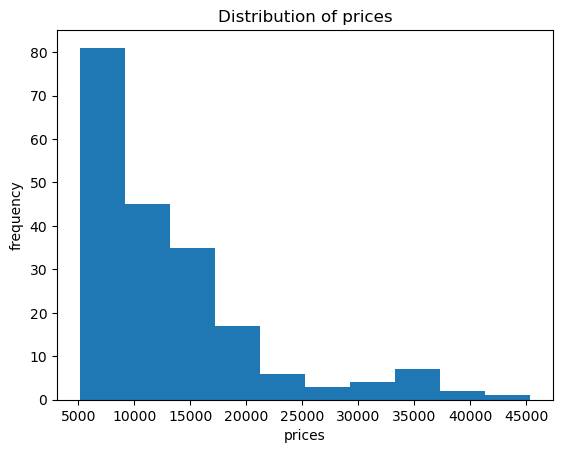

In [71]:
import matplotlib.pyplot as plt

plt.hist(df['price'])
plt.xlabel("prices")
plt.ylabel("frequency")
plt.title("Distribution of prices")
plt.plot()

### Question 39
Create a **bar chart** showing the average price for each body style.


body_style
convertible    21890.500000
hardtop        22208.500000
hatchback       9957.441176
sedan          14459.755319
wagon          12371.960000
Name: price, dtype: float64


<BarContainer object of 5 artists>

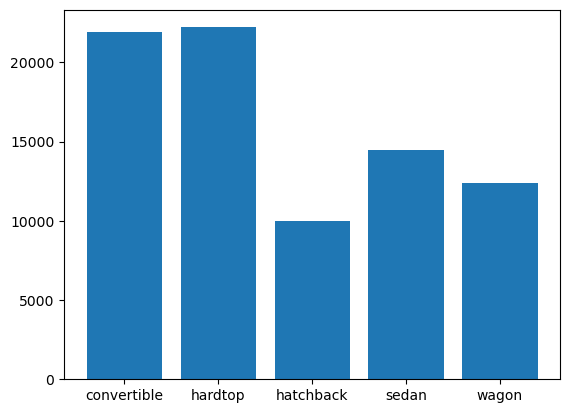

In [ ]:
avg_price =df.groupby('body_style')['price'].mean()
print(avg_price)

plt.bar(avg_price.index ,avg_price.values)

### Question 40
Save `df_clean` as **Automobile_Cleaned.csv** using `to_csv()` without saving the index.


In [76]:
df_clean=df.to_csv('Automobile_Cleaned.csv' ,index=False)

## End of Practice

Try to solve each question independently before checking any reference material.

The main goal is to become comfortable with cleaning and analyzing a dataset that contains numerical values, categories, and missing information before moving to predictive modeling.
